In [48]:
import numpy as npimport 
import matplotlib.pyplot as plt

In [49]:
P1 = np.array([[0.3,   0.4,    0.3   ],
               [0.05,  0.8875, 0.0625],
               [0.3,   0.5,    0.2   ]])

P2 = np.array([[0.5,   0.2,    0.3   ],
               [0.025, 0.9125, 0.0625],
               [0.3,   0.5,    0.2   ]])

transition_probs1 = [
    (0, 0, 0.3),
    (0, 1, 0.4),
    (0, 2, 0.3),
    (1, 0, 0.05),
    (1, 1, 0.8875),
    (1, 2, 0.0625),
    (2, 0, 0.3),
    (2, 1, 0.5),
    (2, 2, 0.2)]

transition_probs2 = [
    (0, 0, 0.5),
    (0, 1, 0.2),
    (0, 2, 0.3),
    (1, 0, 0.025),
    (1, 1, 0.9125),
    (1, 2, 0.0625),
    (2, 0, 0.3),
    (2, 1, 0.5),
    (2, 2, 0.2)]



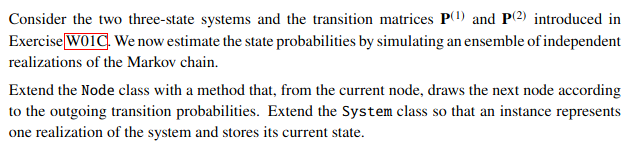

In [50]:
class Node:
    def __init__(self, index):
        self.index = index
        self.neighbors = []

    def add_neighbor(self, other_node, transition_prob):
        self.neighbors.append((other_node, transition_prob))

    def draw_next(self):
        next_node = [next for next, prob in self.neighbors] # What node? [Node0, Node1, Node2]
        probs = [prob for next, prob in self.neighbors]    # What corresponding probability? [p0, p1, p2]
        return np.random.choice(next_node, p=probs)         # Choose node with given probabilites

nodes1 = [Node(i) for i in range(3)]
for i, j, p in transition_probs1:
    nodes1[i].add_neighbor(nodes1[j], p)

nodes2 = [Node(i) for i in range(3)]
for i, j, p in transition_probs2:
    nodes2[i].add_neighbor(nodes2[j], p)

In [51]:
class System():
    def __init__(self, nodes, p0, start_index=0):
        self.nodes = nodes
        self.n_states = len(nodes)
        self.current_node = nodes[start_index]
        self.trajectory = [start_index]

        self.P = np.zeros((self.n_states, self.n_states)) # create 3 x 3 matrix
        for node in nodes:                              # There are three nodes
            for other_node, prob in node.neighbors:     # Node neighbors is a list of all elements in a row, meaning other_node=[0,1,2]          
                self.P[node.index, other_node.index] = prob
        # This is deterministic
        self.p = np.array(p0)                           # What state do we start in? can be a probability i think
        self.history = [self.p.copy()]                  # record what states we enter
        # This is stochastic
        self.current_node = nodes[start_index]

    def step(self):
        self.p = self.p @ self.P                    # Do the step as Eq 19 describes in exercises 
        self.history.append(self.p.copy())          # again, we record steps

    def propagate(self, n):                         # This method just steps n times
        for _ in range(n):
            self.step()
        return self.p

    def next_state(self):
        self.current_node = self.current_node.draw_next()
        self.trajectory.append(self.current_node.index)
        return self.current_node.index

In [52]:
nodes1 = [Node(i) for i in range(3)]
for i, j, p in transition_probs1:
    nodes1[i].add_neighbor(nodes1[j], p)

nodes2 = [Node(i) for i in range(3)]
for i, j, p in transition_probs2:
    nodes2[i].add_neighbor(nodes2[j], p)

In [53]:
n_ensembles = 1000
transitions = 100
ensemble = [System(nodes1, [1, 0, 0], start_index=0) for _ in range(n_ensembles)]

for e in ensemble:
    for _ in range(transitions):
        e.next_state()

state_count = np.zeros(3)
for e in ensemble:
    state_count[e.current_node.index] += 1

p_n = state_count / n_ensembles
print(state_count)
print(p_n)
print(System(nodes1, [1, 0, 0]).propagate(transitions)) 

[ 93. 801. 106.]
[0.093 0.801 0.106]
[0.1 0.8 0.1]


In [54]:
n_ensembles = 100_000
transitions = 10

for name, nodes in [("P(1)", nodes1), ("P(2)", nodes2)]:
    ensemble = [System(nodes, [1, 0, 0], start_index=0) for _ in range(n_ensembles)]

    for e in ensemble:
        for _ in range(transitions):
            e.next_state()

    state_count = np.zeros(3)
    for e in ensemble:
        state_count[e.current_node.index] += 1

    p_n = state_count / n_ensembles
    print(name, state_count, p_n)
    print("exact:", System(nodes, [1, 0, 0]).propagate(transitions))

P(1) [10061. 79857. 10082.] [0.10061 0.79857 0.10082]
exact: [0.10014866 0.79973609 0.10011526]
P(2) [10454. 79292. 10254.] [0.10454 0.79292 0.10254]
exact: [0.10485305 0.79272042 0.10242653]


#### The deterministic calculation will result in the true probability distribution
#### The stochastic result is a statistical estimate instead, while it is close in value there can be some fluctuation around the true value

In [55]:
transitions = 10
exact = System(nodes1, [1, 0, 0]).propagate(transitions)

for N in [100, 1000, 10000, 100000]:
    errs = []
    for r in range(10):                       # repeat to average out the noise
        ensemble = [System(nodes1, [1, 0, 0], start_index=0) for _ in range(N)]
        for e in ensemble:
            for _ in range(transitions):
                e.next_state()
        state_count = np.zeros(3)
        for e in ensemble:
            state_count[e.current_node.index] += 1
        errs.append(np.linalg.norm(state_count / N - exact))
    print(N, np.mean(errs), np.mean(errs) * np.sqrt(N))

100 0.041898069842327856 0.41898069842327856
1000 0.016517818510952315 0.5223392847190023
10000 0.003298275914650141 0.3298275914650141
100000 0.0013529826147614036 0.42785066972561875


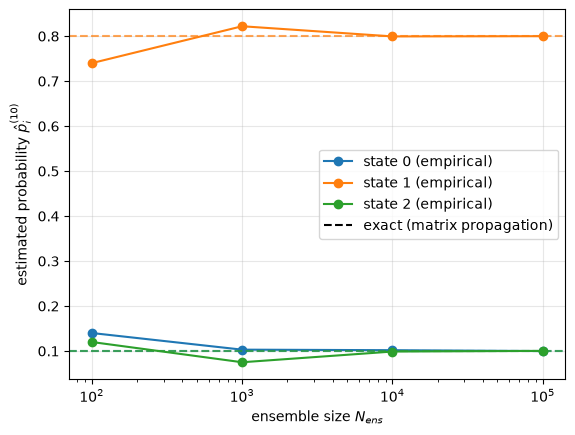

In [58]:
transitions = 10
sizes = [100, 1000, 10000, 100000]
exact = System(nodes1, [1, 0, 0]).propagate(transitions)

p_hat = []
for N in sizes:
    ensemble = [System(nodes1, [1, 0, 0], start_index=0) for _ in range(N)]
    for e in ensemble:
        for _ in range(transitions):
            e.next_state()
    state_count = np.zeros(3)
    for e in ensemble:
        state_count[e.current_node.index] += 1
    p_hat.append(state_count / N)
p_hat = np.array(p_hat)

for i in range(3):
    plt.plot(sizes, p_hat[:, i], "o-", label=f"state {i} (empirical)")
    plt.axhline(exact[i], color=colors[i], linestyle="--", alpha=0.7)
plt.plot([], [], "k--", label="exact (matrix propagation)")
plt.xscale("log")
plt.xlabel("ensemble size $N_{ens}$")
plt.ylabel(r"estimated probability $\hat{p}_i^{(10)}$")
plt.legend()
plt.grid(alpha=0.3)
plt.show()